# Analytical Availability Modeling and Reliability Block Diagrams (RBD)


In [1]:
import sys
import os
from pathlib import Path

current = Path.cwd().resolve()
while current != current.parent:
    if (current / "requirements.txt").exists():
        project_root = current
        break
    current = current.parent
else:
    project_root = Path.cwd().resolve()

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.models.analytical import (
    DEFAULT_BLOCKS,
    HOURS_PER_YEAR,
    MINUTES_PER_YEAR,
    calculate_series_availability,
    calculate_parallel_availability,
    calculate_downtime_hours,
    calculate_downtime_minutes,
    evaluate_scenario_1,
    evaluate_scenario_2,
    evaluate_scenario_3,
    get_all_scenarios_summary,
)
from src.visualization.draw_rbd import (
    draw_rbd_scenario_1,
    draw_rbd_scenario_2,
    draw_rbd_scenario_3,
    draw_rbd_comparison_all,
    generate_all_rbd_diagrams,
)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
print("Environment initialized successfully. Project root:", project_root)

from src.models.analytical_reliability import (
    MTTFMetrics,
    calculate_component_reliability,
    calculate_parallel_reliability,
    calculate_reliability_baseline,
    calculate_reliability_redundant,
    calculate_reliability_scenario_3,
    calculate_mttf_baseline,
    calculate_mttf_redundant_closed_form,
    calculate_mttf_redundant_numerical,
    calculate_mttf_scenario_3_closed_form,
    evaluate_mttf_metrics,
    plot_reliability_curves,
)
from src.models.pareto import (
    SubsystemDowntimeContribution,
    ParetoAnalysisResult,
    compute_subsystem_downtime_contributions,
    evaluate_pareto_analysis,
    get_pareto_dataframe,
    compute_bottleneck_shift_summary,
)
from src.visualization.plot_pareto import (
    plot_pareto_analysis,
    plot_pareto_single_scenario,
    plot_pareto_all_scenarios_3panel,
    generate_all_pareto_diagrams,
)


Environment initialized successfully. Project root: /home/xavier/dev/system-reliability-engineering


## 1. Mathematical Modeling Framework

In [2]:
block_data = []

for code, b in DEFAULT_BLOCKS.items():
    mu_i = 1.0 / b.mttr_hours
    lambda_i = b.lambda_base
    mtbf_i = b.mtbf_hours_base
    downtime_base_h = b.annual_downtime_hours_base
    downtime_base_min = downtime_base_h * 60.0

    # Redundant metrics
    a_red = b.availability_redundant
    downtime_red_h = (1.0 - a_red) * HOURS_PER_YEAR if a_red is not None else np.nan
    downtime_red_min = downtime_red_h * 60.0 if a_red is not None else np.nan
    
    block_data.append({
        "Block Code": b.code,
        "Subsystem Name": b.name,
        "Architectural Tier": b.tier,
        "Baseline SLA ($A_i$)": f"{b.availability_base * 100:.2f}%",
        r"Redundant SLA ($A_{i,\text{red}}$)": f"{a_red * 100:.4f}%" if a_red else "N/A",
        "MTTR (h)": b.mttr_hours,
        r"Failure Rate $\lambda$ ($10^{-3}$ h$^{-1}$)": lambda_i * 1000.0,
        "MTBF (hours)": mtbf_i,
        "Baseline Downtime (h/yr)": downtime_base_h,
        "Baseline Downtime (min/yr)": downtime_base_min,
        "Redundant Downtime (h/yr)": downtime_red_h,
        "Cloud Provider Reference": b.reference_sla,
    })

df_blocks = pd.DataFrame(block_data)
display(df_blocks[[
    "Block Code", "Subsystem Name", "Architectural Tier", 
    "Baseline SLA ($A_i$)", r"Redundant SLA ($A_{i,\text{red}}$)", 
    "MTTR (h)", r"Failure Rate $\lambda$ ($10^{-3}$ h$^{-1}$)", 
    "MTBF (hours)", "Baseline Downtime (h/yr)", "Redundant Downtime (h/yr)"
]])


,Block Code,Subsystem Name,Architectural Tier,Baseline SLA ($A_i$),"Redundant SLA ($A_{i,\text{red}}$)",MTTR (h),Failure Rate $\lambda$ ($10^{-3}$ h$^{-1}$),MTBF (hours),Baseline Downtime (h/yr),Redundant Downtime (h/yr)
0,LB,Load Balancer,Ingress & Routing,99.99%,99.9900%,0.250000,0.400040,2499.750000,0.876000,0.876000
1,App,Application Server,Business Logic & Auth,99.50%,99.9900%,0.500000,10.050251,99.500000,43.800000,0.876000
2,DB,Transactional Database,Data Persistence,99.50%,99.9500%,1.000000,5.025126,199.000000,43.800000,4.380000
3,PGW,Payment Gateway,External Settlement Network,99.95%,100.0000%,0.500000,1.000500,999.500000,4.380000,0.002190


## 2. Reliability Block Diagrams (RBD) Theoretical Formulations

Generating RBD diagrams for all scenarios...
Saved: /home/xavier/dev/system-reliability-engineering/reports/figures/rbd_scenario_1.pdf and /home/xavier/dev/system-reliability-engineering/reports/figures/rbd_scenario_1.png
Saved: /home/xavier/dev/system-reliability-engineering/reports/figures/rbd_scenario_2.pdf and /home/xavier/dev/system-reliability-engineering/reports/figures/rbd_scenario_2.png
Saved: /home/xavier/dev/system-reliability-engineering/reports/figures/rbd_scenario_3.pdf and /home/xavier/dev/system-reliability-engineering/reports/figures/rbd_scenario_3.png
Saved: /home/xavier/dev/system-reliability-engineering/reports/figures/rbd_comparison_all.pdf and /home/xavier/dev/system-reliability-engineering/reports/figures/rbd_comparison_all.png
All RBD diagrams successfully generated!
Diagrams successfully exported to: /home/xavier/dev/system-reliability-engineering/reports/figures


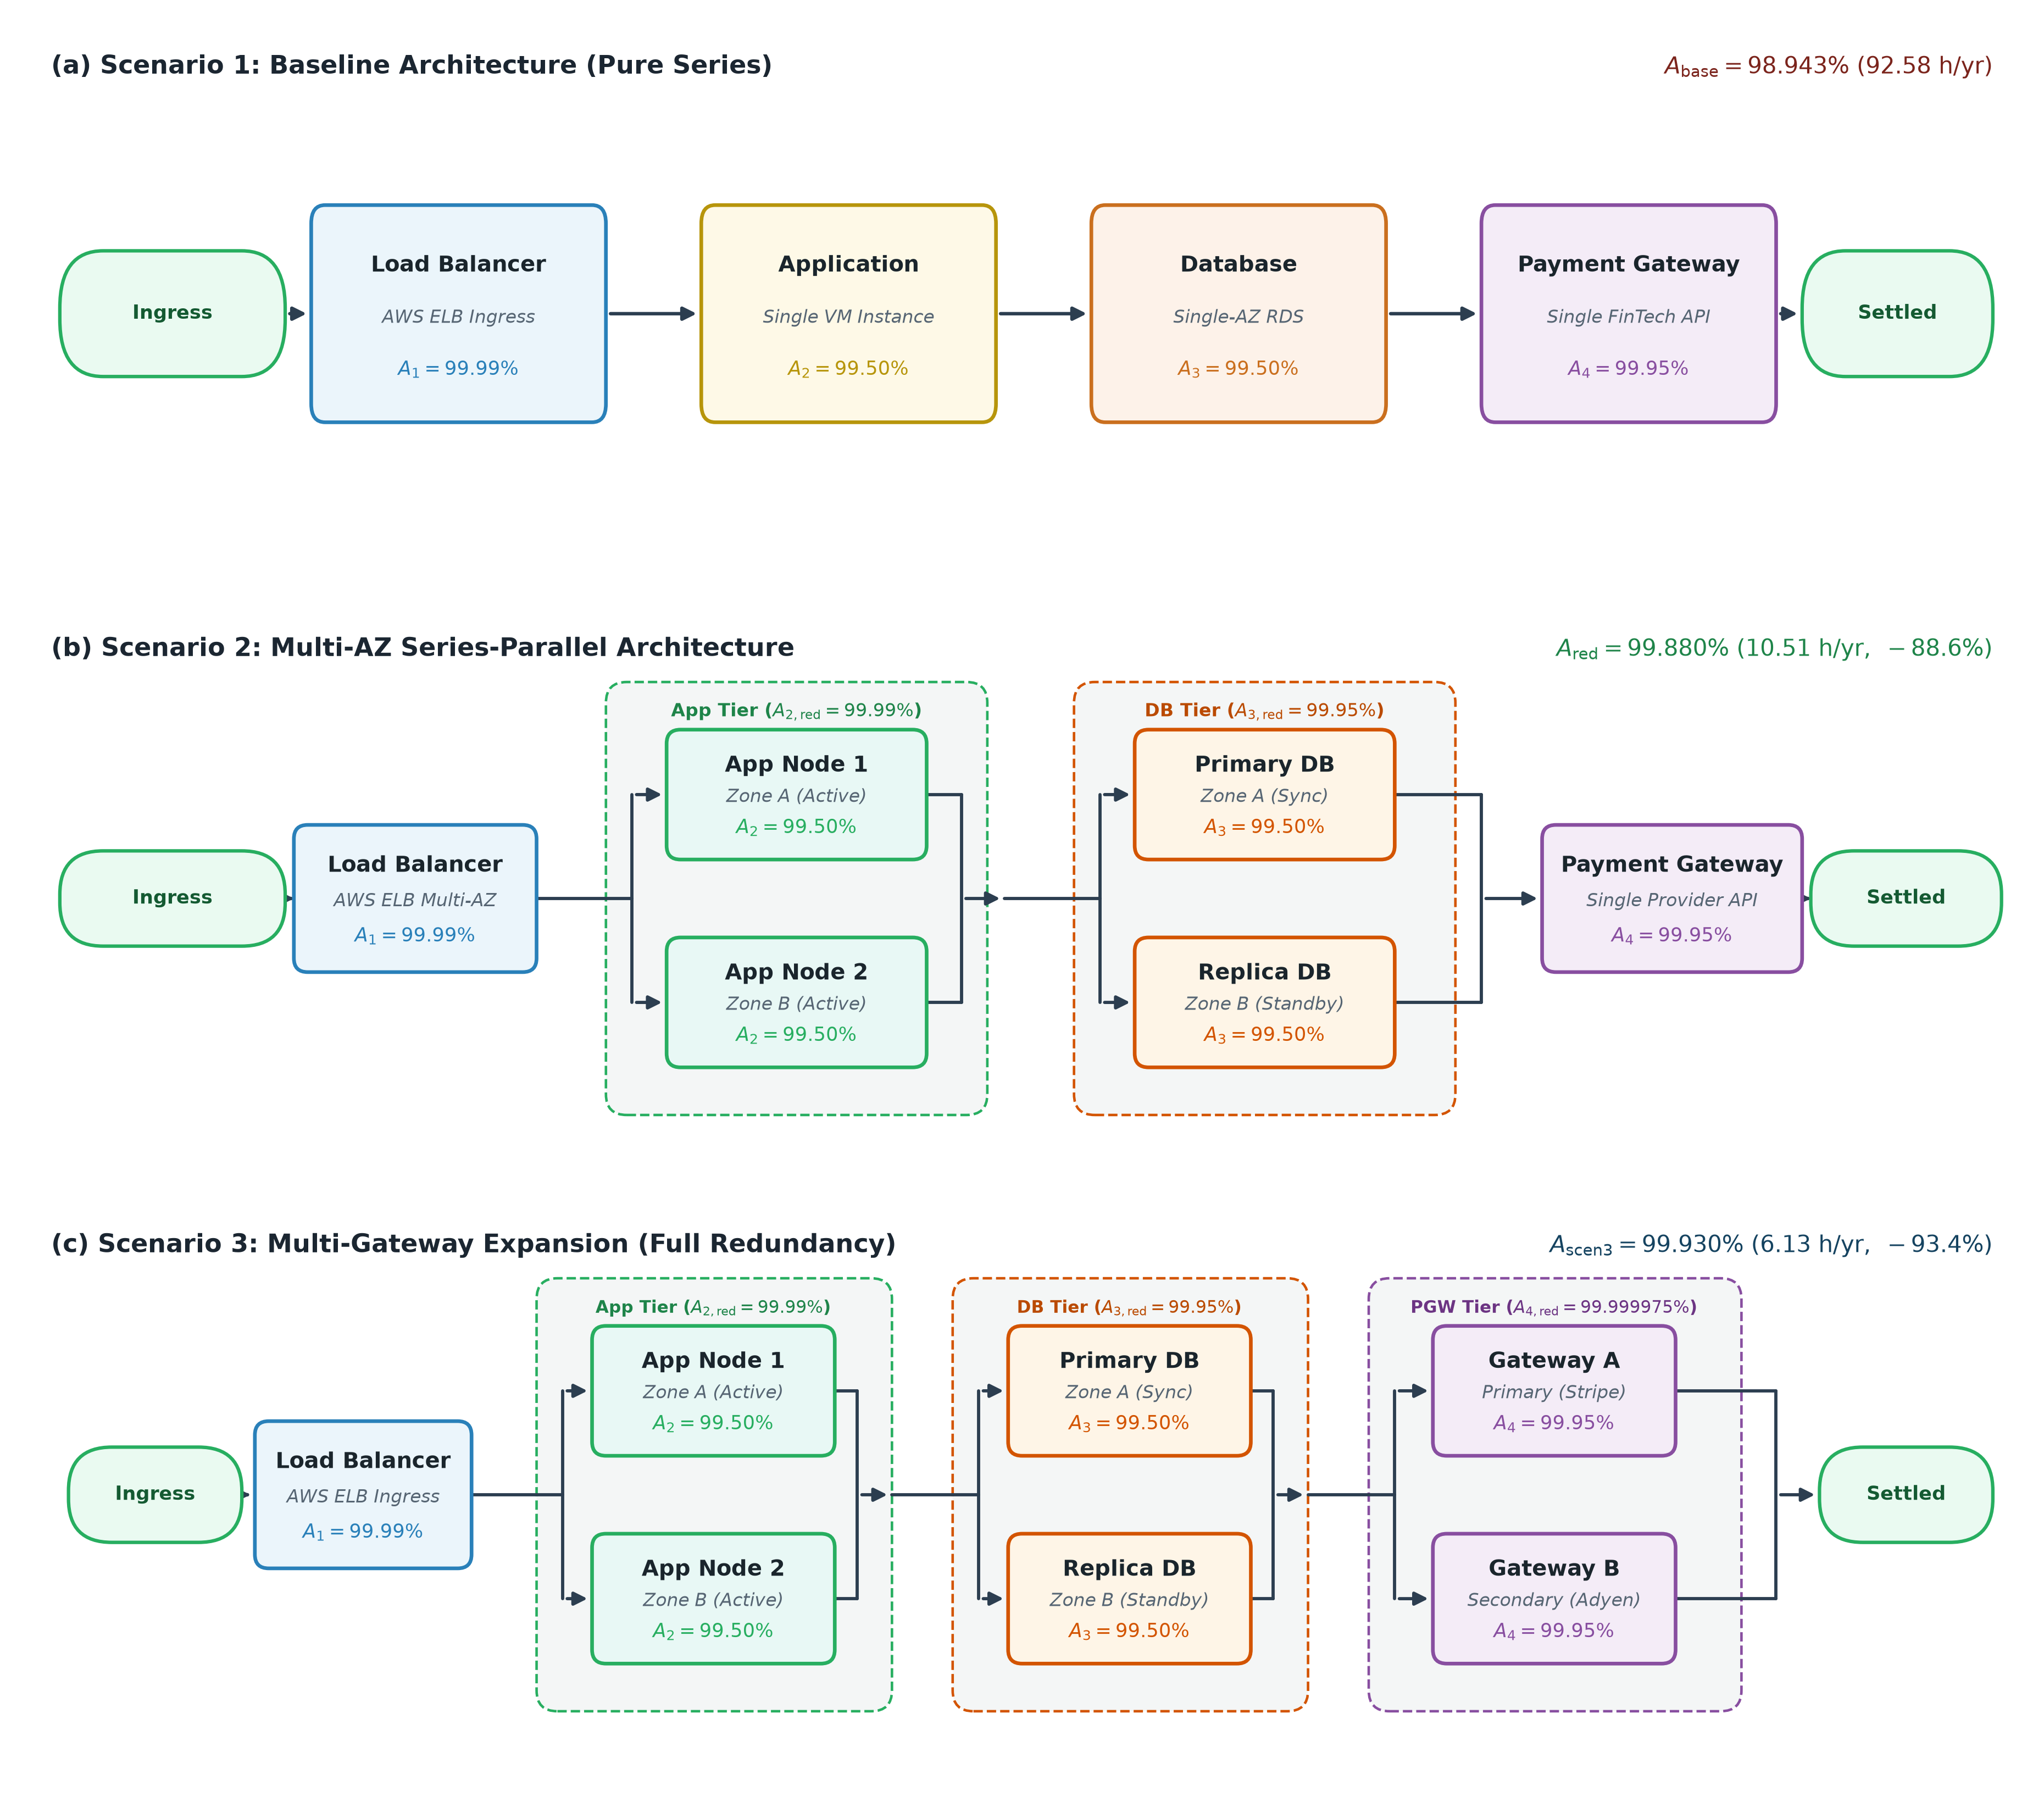

In [3]:
figures_dir = project_root / "reports" / "figures"
generate_all_rbd_diagrams()

print(f"Diagrams successfully exported to: {figures_dir}")

img_path = figures_dir / "rbd_comparison_all.png"
if img_path.exists():
    display(Image(filename=str(img_path), width=900))
else:
    print("Diagram image file not found.")


## 3. Scenario 1: Baseline Architecture (Pure Series RBD)

In [4]:
s1 = evaluate_scenario_1()

print("SCENARIO 1: BASELINE ARCHITECTURE (PURE SERIES)")

print(f"\nSubsystem Availabilities:")
for block, a in s1.block_availabilities.items():
    print(f"{block}: A_{block} = {a:.4f} ({a*100:.2f}%)")

print(f"\nSystem Availability (A_base): {s1.system_availability:.10f} ({s1.system_availability*100:.3f}%)")
print(f"System Unavailability (U_base): {s1.unavailability:.10f} ({s1.unavailability*100:.4f}%)")
print(f"Expected Annual Downtime (hours): {s1.annual_downtime_hours:.4f} hours/year")
print(f"Expected Annual Downtime (mins): {s1.annual_downtime_minutes:.2f} minutes/year")


SCENARIO 1: BASELINE ARCHITECTURE (PURE SERIES)

Subsystem Availabilities:
LB: A_LB = 0.9999 (99.99%)
App: A_App = 0.9950 (99.50%)
DB: A_DB = 0.9950 (99.50%)
PGW: A_PGW = 0.9995 (99.95%)

System Availability (A_base): 0.9894310345 (98.943%)
System Unavailability (U_base): 0.0105689655 (1.0569%)
Expected Annual Downtime (hours): 92.5841 hours/year
Expected Annual Downtime (mins): 5555.05 minutes/year


## 4. Scenario 2: Multi-AZ Series-Parallel Architecture

In [5]:
s2 = evaluate_scenario_2()

print("SCENARIO 2: MULTI-AZ REDUNDANT ARCHITECTURE (SERIES-PARALLEL)")

print(f"\nSubsystem Availabilities:")
for block, a in s2.block_availabilities.items():
    print(f"{block}: A_{block} = {a:.4f} ({a*100:.2f}%)")

print(f"\nSystem Availability (A_red): {s2.system_availability:.10f} ({s2.system_availability*100:.3f}%)")
print(f"System Unavailability (U_red): {s2.unavailability:.10f} ({s2.unavailability*100:.4f}%)")
print(f"Expected Annual Downtime (hours): {s2.annual_downtime_hours:.4f} hours/year")
print(f"Expected Annual Downtime (mins): {s2.annual_downtime_minutes:.2f} minutes/year")
print(f"Absolute Downtime Reduction: {s2.absolute_reduction_hours_vs_baseline:.4f} hours/year saved")
print(f"Relative Downtime Reduction: {s2.relative_reduction_vs_baseline_pct:.2f}% reduction vs baseline")



SCENARIO 2: MULTI-AZ REDUNDANT ARCHITECTURE (SERIES-PARALLEL)

Subsystem Availabilities:
LB: A_LB = 0.9999 (99.99%)
App: A_App = 0.9999 (99.99%)
DB: A_DB = 0.9995 (99.95%)
PGW: A_PGW = 0.9995 (99.95%)

System Availability (A_red): 0.9988004599 (99.880%)
System Unavailability (U_red): 0.0011995401 (0.1200%)
Expected Annual Downtime (hours): 10.5080 hours/year
Expected Annual Downtime (mins): 630.48 minutes/year
Absolute Downtime Reduction: 82.0762 hours/year saved
Relative Downtime Reduction: 88.65% reduction vs baseline


## 5. Scenario 3: Multi-Gateway Expansion Architecture

In [6]:
s3 = evaluate_scenario_3()


print("SCENARIO 3: MULTI-GATEWAY EXPANSION ARCHITECTURE")

print(f"\nSubsystem Availabilities:")
for block, a in s3.block_availabilities.items():
    print(f"{block}: A_{block} = {a:.8f} ({a*100:.6f}%)")

print(f"\nSystem Availability (A_scen3): {s3.system_availability:.10f} ({s3.system_availability*100:.3f}%)")
print(f"System Unavailability (U_scen3): {s3.unavailability:.10f} ({s3.unavailability*100:.4f}%)")
print(f"Expected Annual Downtime (hours): {s3.annual_downtime_hours:.4f} hours/year")
print(f"Expected Annual Downtime (mins): {s3.annual_downtime_minutes:.2f} minutes/year")
print(f"Absolute Reduction vs Baseline: {s3.absolute_reduction_hours_vs_baseline:.4f} hours/year saved")
print(f"Relative Reduction vs Baseline: {s3.relative_reduction_vs_baseline_pct:.2f}% reduction")
print(f"Reduction vs Scenario 2 (Multi-AZ): {s2.annual_downtime_hours - s3.annual_downtime_hours:.4f} h/year saved ({(s2.annual_downtime_hours - s3.annual_downtime_hours)/s2.annual_downtime_hours * 100:.2f}%)")



SCENARIO 3: MULTI-GATEWAY EXPANSION ARCHITECTURE

Subsystem Availabilities:
LB: A_LB = 0.99990000 (99.990000%)
App: A_App = 0.99990000 (99.990000%)
DB: A_DB = 0.99950000 (99.950000%)
PGW: A_PGW = 0.99999975 (99.999975%)

System Availability (A_scen3): 0.9992998602 (99.930%)
System Unavailability (U_scen3): 0.0007001398 (0.0700%)
Expected Annual Downtime (hours): 6.1332 hours/year
Expected Annual Downtime (mins): 367.99 minutes/year
Absolute Reduction vs Baseline: 86.4509 hours/year saved
Relative Reduction vs Baseline: 93.38% reduction
Reduction vs Scenario 2 (Multi-AZ): 4.3747 h/year saved (41.63%)


## 6. Comprehensive Comparative Synthesis

,Scenario,Name,Availability (%),Unavailability (%),Downtime (h/yr),Downtime (min/yr),Reduction vs S1 (%),Hours Saved vs S1 (h)
0,Scenario 1,Scenario 1 (Baseline Series),98.943103,1.056897,92.584138,5555.048266,0.000000,0.000000
1,Scenario 2,Scenario 2 (Multi-AZ Series-Parallel),99.880046,0.119954,10.507971,630.478256,88.650355,82.076167
2,Scenario 3,Scenario 3 (Multi-Gateway Expansion),99.929986,0.070014,6.133225,367.993495,93.375512,86.450913


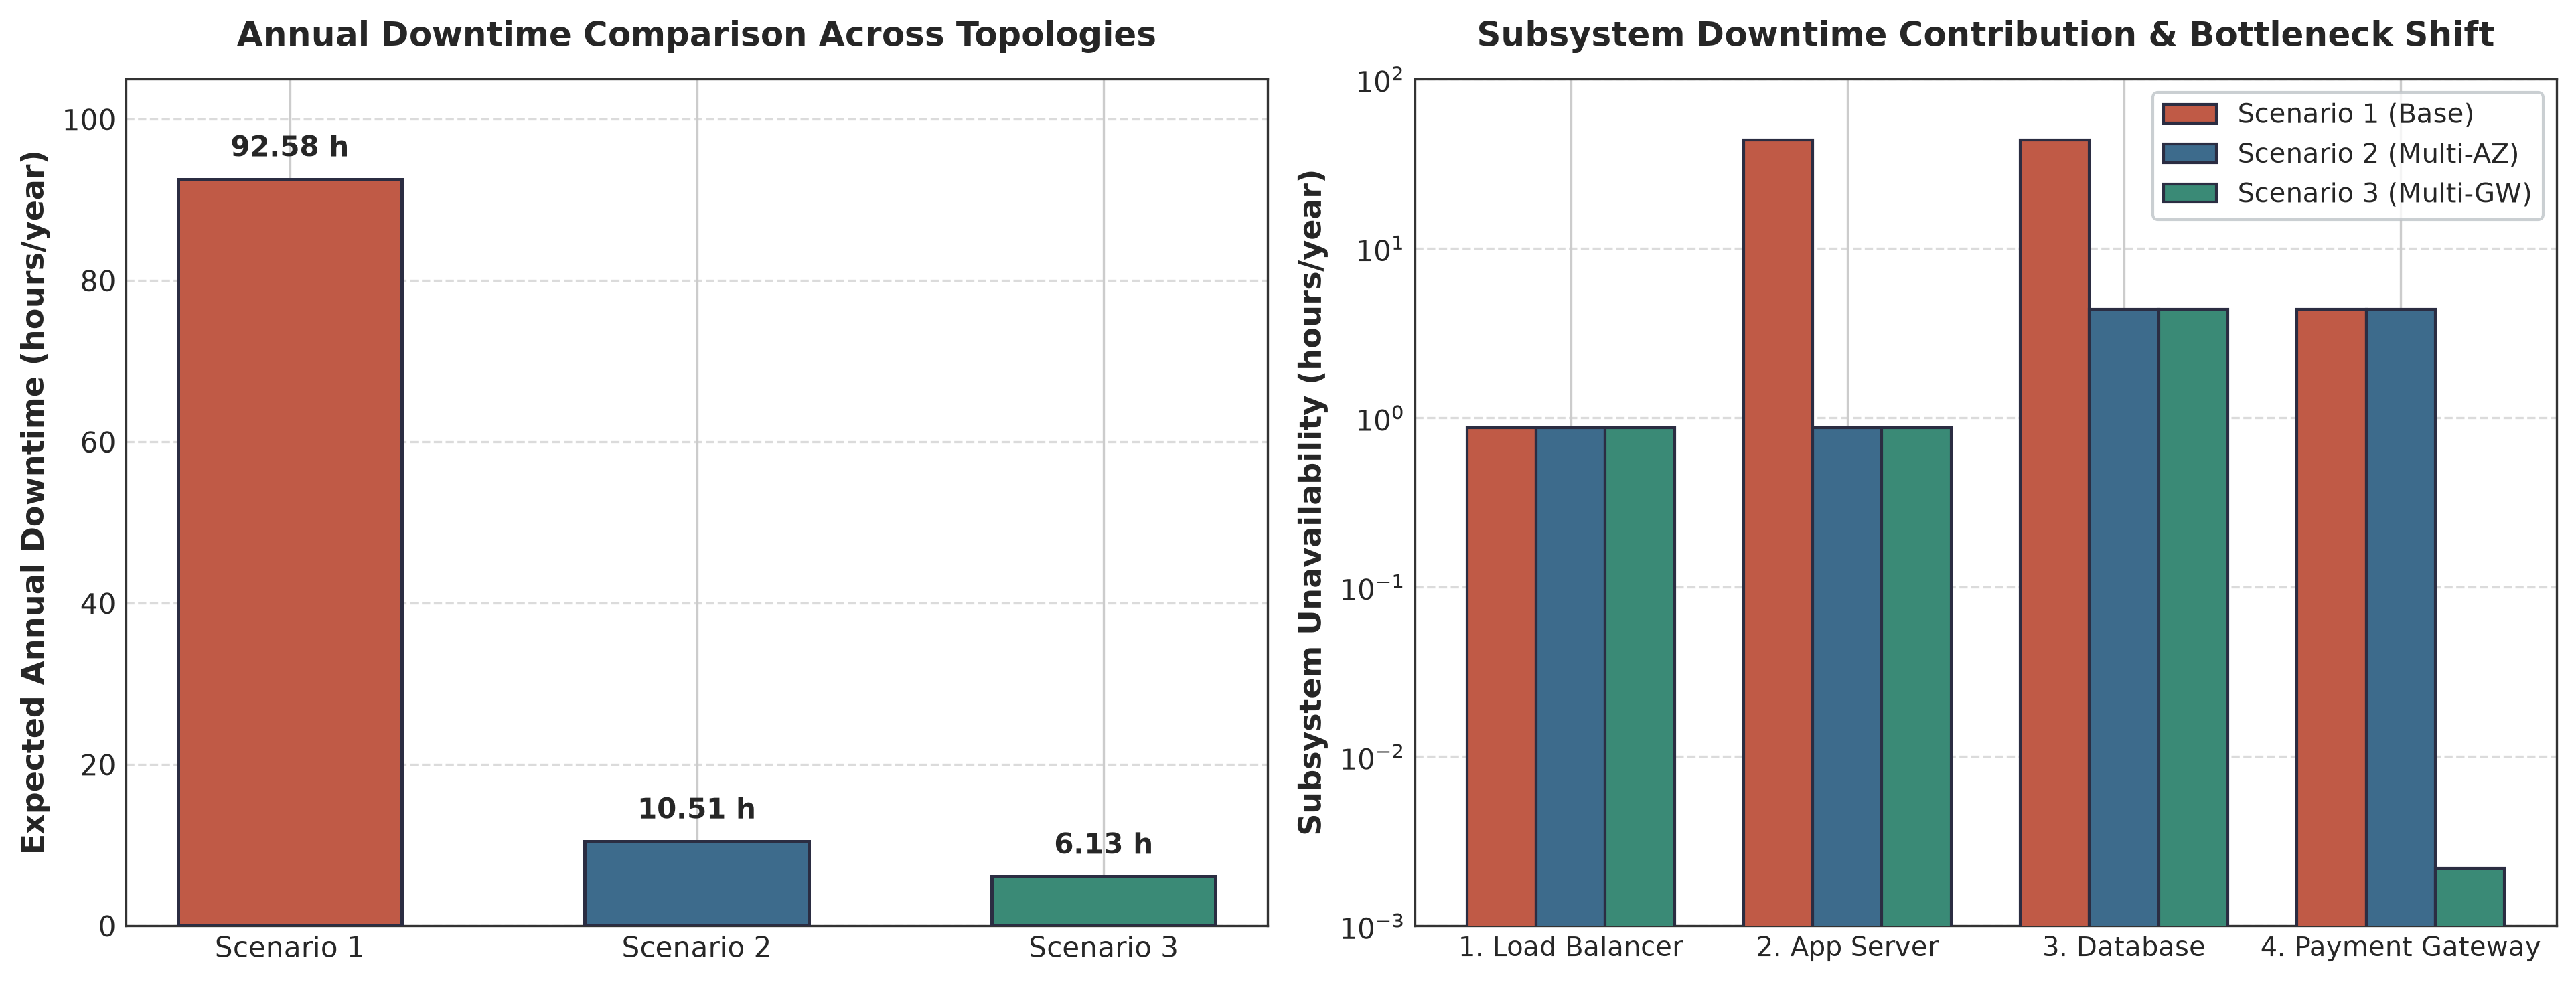

Comparison chart exported to: /home/xavier/dev/system-reliability-engineering/reports/figures/annual_downtime_comparison.png


In [7]:
summaries = get_all_scenarios_summary()

comp_rows = []
for s in summaries:
    comp_rows.append({
        "Scenario": f"Scenario {s.scenario_id}",
        "Name": s.name,
        "Availability (%)": s.system_availability * 100.0,
        "Unavailability (%)": s.unavailability * 100.0,
        "Downtime (h/yr)": s.annual_downtime_hours,
        "Downtime (min/yr)": s.annual_downtime_minutes,
        "Reduction vs S1 (%)": s.relative_reduction_vs_baseline_pct,
        "Hours Saved vs S1 (h)": s.absolute_reduction_hours_vs_baseline,
    })

df_comp = pd.DataFrame(comp_rows)
display(df_comp)

# Plot publication-grade comparative bar charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

scenarios = [f"Scenario {s.scenario_id}" for s in summaries]
downtimes = [s.annual_downtime_hours for s in summaries]
availabilities = [s.system_availability * 100.0 for s in summaries]
colors = ["#C05A46", "#3D6B8C", "#3A8A76"]

# Subplot 1 Annual Downtime
bars1 = ax1.bar(scenarios, downtimes, color=colors, width=0.55, edgecolor="#2B2D42", linewidth=1.2, zorder=3)
ax1.set_ylabel("Expected Annual Downtime (hours/year)", fontsize=11, fontweight="bold")
ax1.set_title("Annual Downtime Comparison Across Topologies", fontsize=12, fontweight="bold", pad=12)
ax1.set_ylim(0, 105)
ax1.grid(axis="y", linestyle="--", alpha=0.7, zorder=0)

for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 2.0, f"{yval:.2f} h", ha="center", va="bottom", fontsize=10, fontweight="bold")

# Subplot 2 Subsystem Downtime Contribution Breakdown
block_names = ["LB", "App", "DB", "PGW"]
s1_contrib = [DEFAULT_BLOCKS[b].annual_downtime_hours_base for b in block_names]
s2_contrib = [
    DEFAULT_BLOCKS["LB"].annual_downtime_hours_base,
    (1 - DEFAULT_BLOCKS["App"].availability_redundant) * HOURS_PER_YEAR,
    (1 - DEFAULT_BLOCKS["DB"].availability_redundant) * HOURS_PER_YEAR,
    DEFAULT_BLOCKS["PGW"].annual_downtime_hours_base,
]
s3_contrib = [
    DEFAULT_BLOCKS["LB"].annual_downtime_hours_base,
    (1 - DEFAULT_BLOCKS["App"].availability_redundant) * HOURS_PER_YEAR,
    (1 - DEFAULT_BLOCKS["DB"].availability_redundant) * HOURS_PER_YEAR,
    (1 - DEFAULT_BLOCKS["PGW"].availability_redundant) * HOURS_PER_YEAR,
]

x = np.arange(len(block_names))
w = 0.25

b1 = ax2.bar(x - w, s1_contrib, width=w, label="Scenario 1 (Base)", color="#C05A46", edgecolor="#2B2D42", lw=1, zorder=3)
b2 = ax2.bar(x, s2_contrib, width=w, label="Scenario 2 (Multi-AZ)", color="#3D6B8C", edgecolor="#2B2D42", lw=1, zorder=3)
b3 = ax2.bar(x + w, s3_contrib, width=w, label="Scenario 3 (Multi-GW)", color="#3A8A76", edgecolor="#2B2D42", lw=1, zorder=3)

ax2.set_xticks(x)
ax2.set_xticklabels(["1. Load Balancer", "2. App Server", "3. Database", "4. Payment Gateway"], fontsize=9.5)
ax2.set_ylabel("Subsystem Unavailability (hours/year)", fontsize=11, fontweight="bold")
ax2.set_title("Subsystem Downtime Contribution & Bottleneck Shift", fontsize=12, fontweight="bold", pad=12)
ax2.set_yscale("log")
ax2.set_ylim(0.001, 100)
ax2.grid(axis="y", linestyle="--", alpha=0.7, zorder=0)
ax2.legend(frameon=True, facecolor="white", edgecolor="#BDC3C7", fontsize=9.5)

plt.tight_layout()
fig_path = project_root / "reports" / "figures" / "annual_downtime_comparison.png"
fig_path_pdf = project_root / "reports" / "figures" / "annual_downtime_comparison.pdf"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
fig.savefig(fig_path_pdf, format="pdf", bbox_inches="tight")
plt.show()
print(f"Comparison chart exported to: {fig_path}")


## 7. Time-Dependent Reliability Functions $R(t)$ and Analytical MTTF Gain

In [8]:
metrics = evaluate_mttf_metrics()


print("ANALYTICAL TIME-DEPENDENT RELIABILITY & MTTF GAIN)")

print(f"\nBaseline Series MTTF (MTTF_base): {metrics.mttf_base_hours:10.4f} hours")
print(f"Multi-AZ Redundant MTTF (MTTF_red): {metrics.mttf_red_hours:10.4f} hours")
print(f"Scenario 3 Multi-GW MTTF (MTTF_scen3): {metrics.mttf_scen3_hours:10.4f} hours")

print(f"\nAbsolute MTTF Gain (S2 vs S1): +{metrics.delta_mttf_hours:10.4f} hours")
print(f"Relative MTTF Improvement (S2 vs S1): +{metrics.mttf_gain_pct:10.2f}%")
print(f"MTTF Multiplication Factor: {metrics.mttf_gain_factor:10.4f}x")
print(f"Scenario 3 Relative Gain vs S1: +{metrics.mttf_gain_scen3_pct:10.2f}%")



mttf_rows = [
    {
        "Scenario": "Scenario 1 (Baseline Series)",
        "Topology": "Pure Series (LB -> App -> DB -> PGW)",
        "MTTF (hours)": metrics.mttf_base_hours,
        "MTTF Gain vs S1 (hours)": 0.0,
        "MTTF Gain vs S1 (%)": 0.0,
        "MTTF Multiplier": 1.0,
        "R(24h)": calculate_reliability_baseline(24.0),
        "R(72h)": calculate_reliability_baseline(72.0),
    },
    {
        "Scenario": "Scenario 2 (Multi-AZ)",
        "Topology": "Series-Parallel (Multi-AZ App & DB)",
        "MTTF (hours)": metrics.mttf_red_hours,
        "MTTF Gain vs S1 (hours)": metrics.delta_mttf_hours,
        "MTTF Gain vs S1 (%)": metrics.mttf_gain_pct,
        "MTTF Multiplier": metrics.mttf_gain_factor,
        "R(24h)": calculate_reliability_redundant(24.0),
        "R(72h)": calculate_reliability_redundant(72.0),
    },
    {
        "Scenario": "Scenario 3 (Multi-Gateway)",
        "Topology": "Full Redundancy (+ Dual Payment Gateways)",
        "MTTF (hours)": metrics.mttf_scen3_hours,
        "MTTF Gain vs S1 (hours)": metrics.mttf_scen3_hours - metrics.mttf_base_hours,
        "MTTF Gain vs S1 (%)": metrics.mttf_gain_scen3_pct,
        "MTTF Multiplier": metrics.mttf_scen3_hours / metrics.mttf_base_hours,
        "R(24h)": calculate_reliability_scenario_3(24.0),
        "R(72h)": calculate_reliability_scenario_3(72.0),
    },
]

df_mttf = pd.DataFrame(mttf_rows)
display(df_mttf)

ANALYTICAL TIME-DEPENDENT RELIABILITY & MTTF GAIN)

Baseline Series MTTF (MTTF_base):    60.6946 hours
Multi-AZ Redundant MTTF (MTTF_red):   106.0570 hours
Scenario 3 Multi-GW MTTF (MTTF_scen3):   114.0535 hours

Absolute MTTF Gain (S2 vs S1): +   45.3624 hours
Relative MTTF Improvement (S2 vs S1): +     74.74%
MTTF Multiplication Factor:     1.7474x
Scenario 3 Relative Gain vs S1: +     87.91%


,Scenario,Topology,MTTF (hours),MTTF Gain vs S1 (hours),MTTF Gain vs S1 (%),MTTF Multiplier,R(24h),R(72h)
0,Scenario 1 (Baseline Series),Pure Series (LB -> App -> DB -> PGW),60.694649,0.000000,0.000000,1.000000,0.673396,0.305359
1,Scenario 2 (Multi-AZ),Series-Parallel (Multi-AZ App & DB),106.057027,45.362378,74.738678,1.747387,0.910623,0.603066
2,Scenario 3 (Multi-Gateway),Full Redundancy (+ Dual Payment Gateways),114.053524,53.358876,87.913641,1.879136,0.932228,0.644980


### 7.1 Mission Reliability Curves $R(t)$ and Operational Horizon Analysis

Saved: /home/xavier/dev/system-reliability-engineering/reports/figures/reliability_curves_comparison.pdf and /home/xavier/dev/system-reliability-engineering/reports/figures/reliability_curves_comparison.png


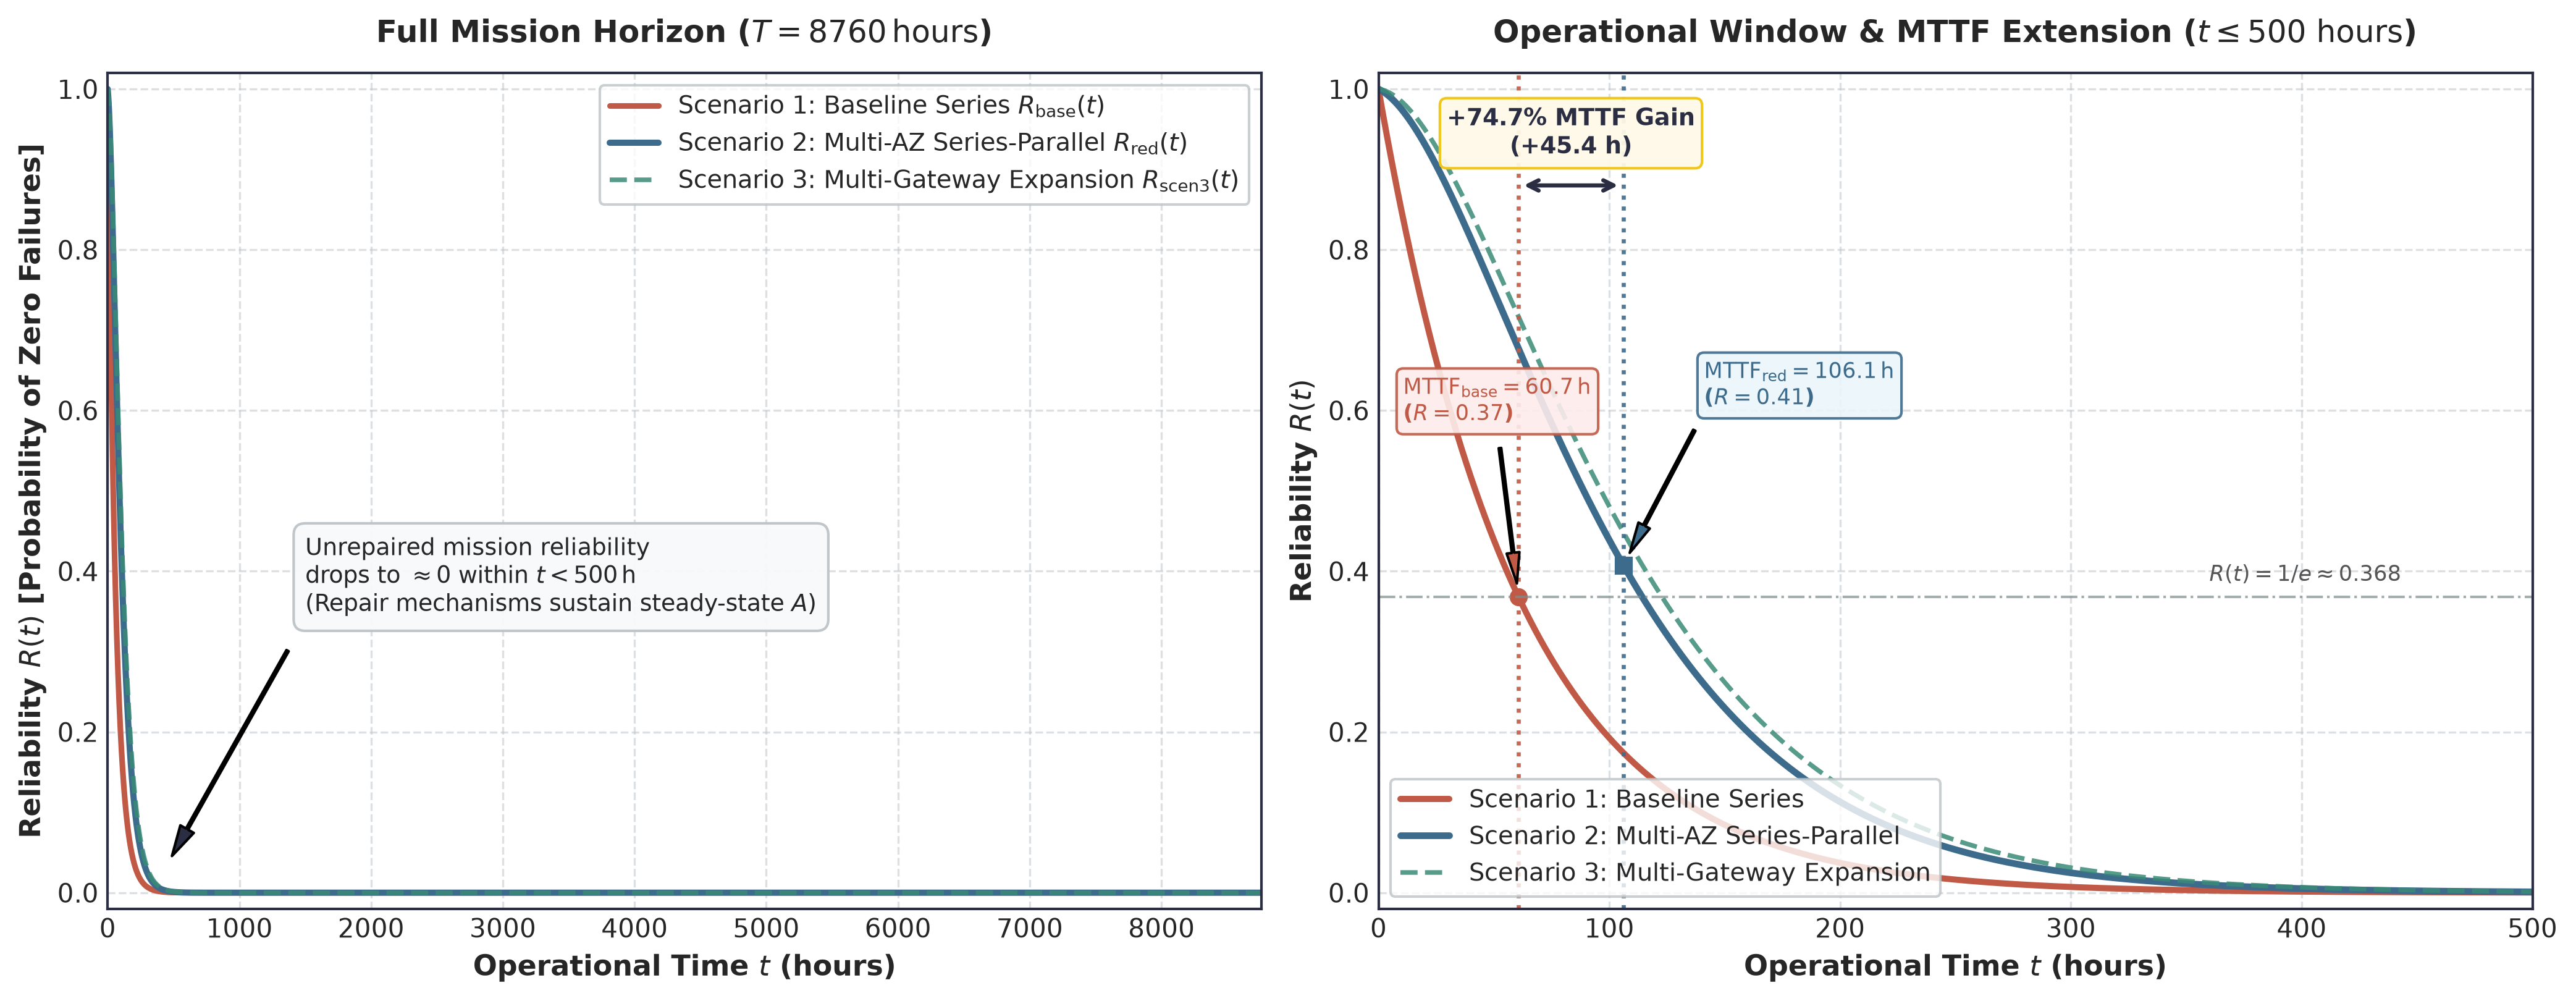

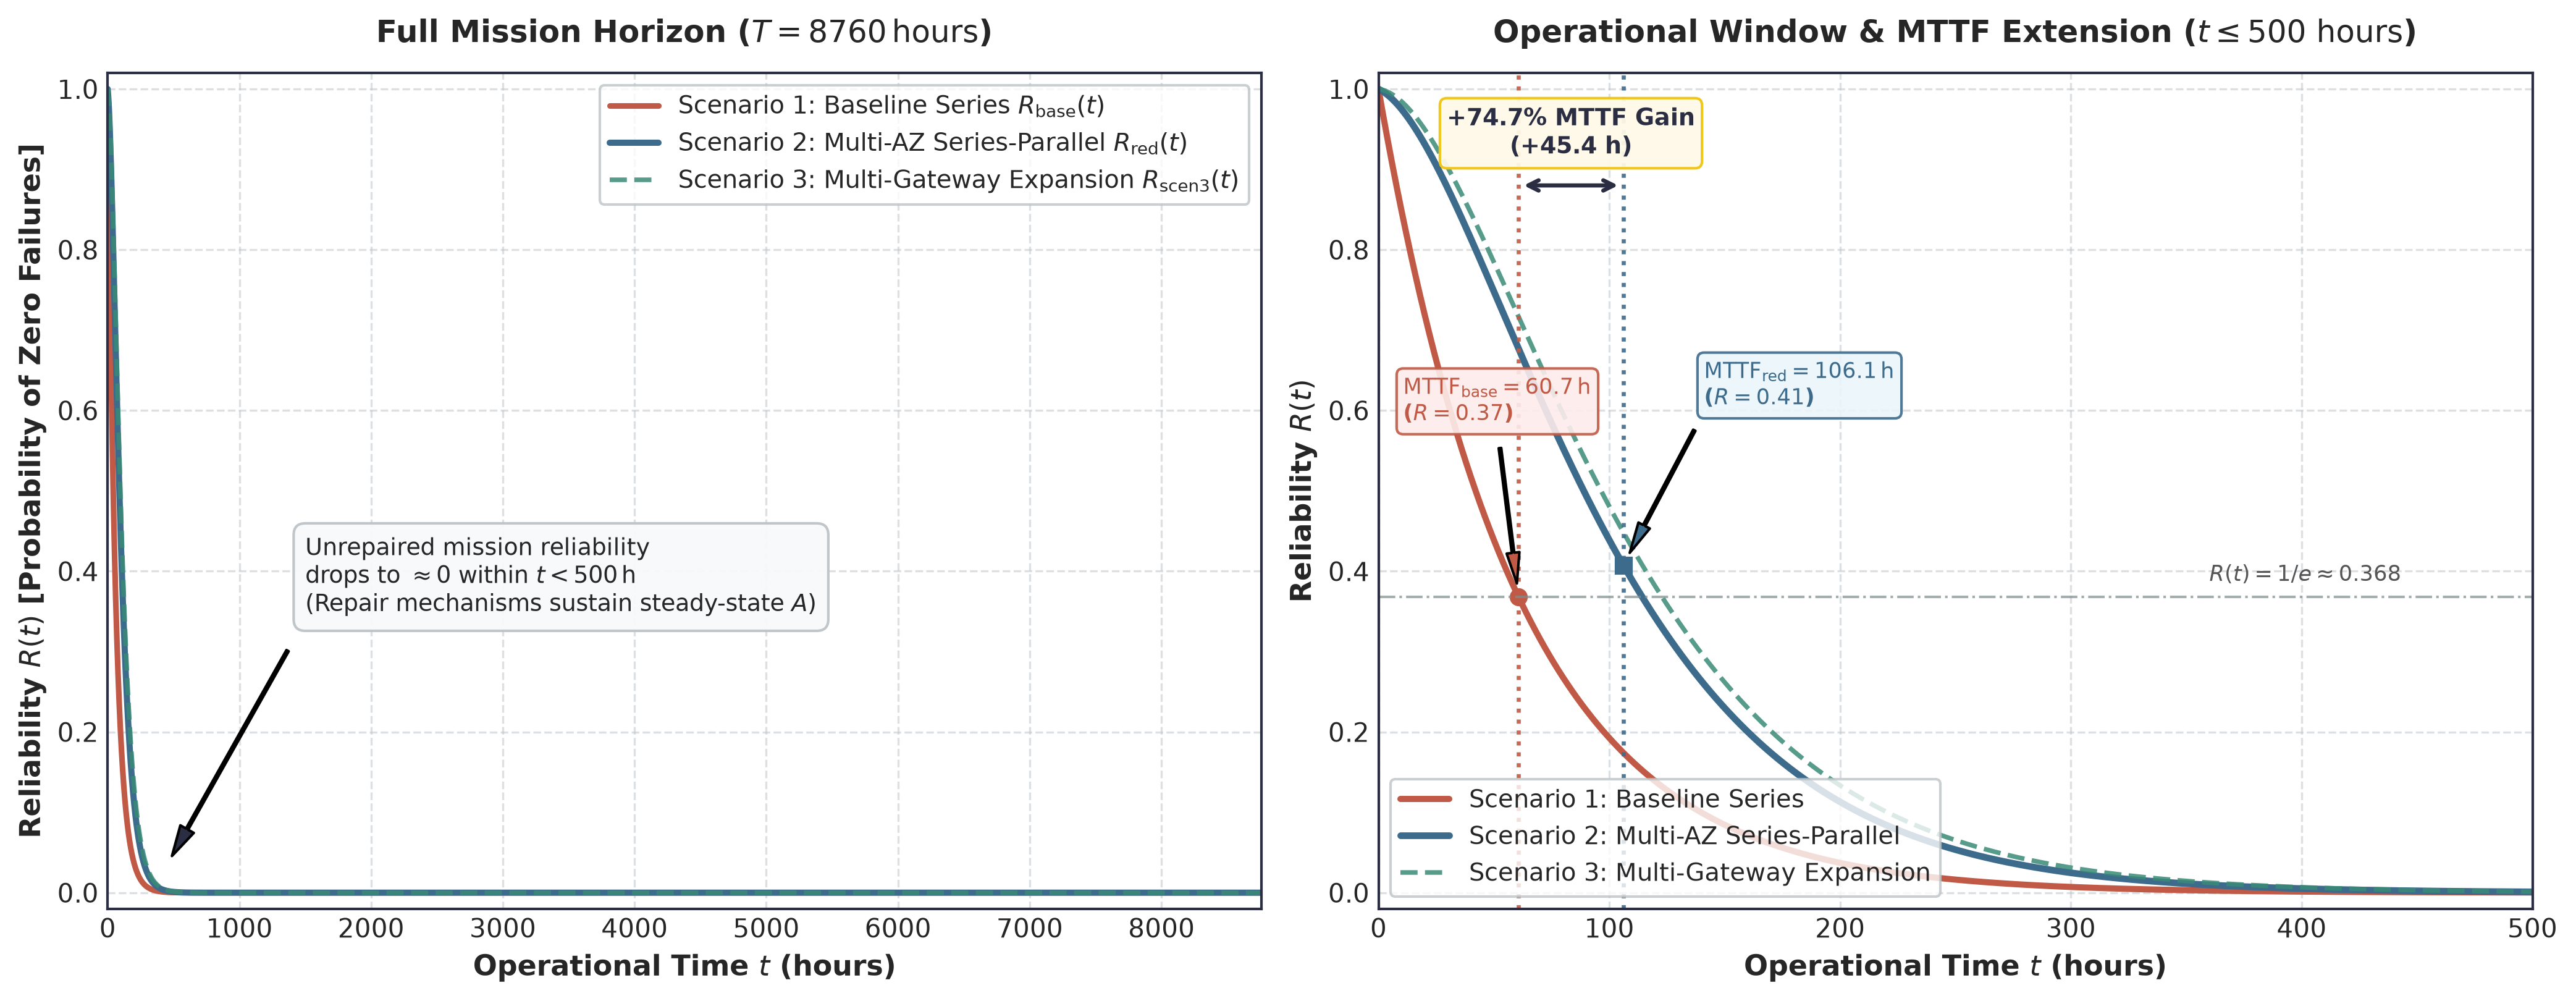

In [9]:
fig_rel = plot_reliability_curves(output_dir=figures_dir)
plt.show()

rel_img_path = figures_dir / "reliability_curves_comparison.png"
if rel_img_path.exists():
    display(Image(filename=str(rel_img_path), width=900))
else:
    print("Reliability comparison image not found.")

## 8. Subsystem Unavailability & Downtime Pareto Analysis

In [10]:
pareto_results = evaluate_pareto_analysis()
shifts = compute_bottleneck_shift_summary(pareto_results)


print("SUBSYSTEM UNAVAILABILITY & DOWNTIME PARETO ANALYSIS")

print(f"\nScenario 1 Internal Tier (App + DB) Share: {shifts['s1_internal_share_pct']:.2f}%")
print(f"Scenario 2 Internal Tier (App + DB) Share: {shifts['s2_internal_share_pct']:.2f}%")
print(f"Internal Tier Downtime Reduction: -{shifts['internal_tier_reduction_pct']:.2f}%")

print(f"\nPayment Gateway Relative Share (S1 -> S2): {shifts['s1_pgw_share_pct']:.2f}% -> {shifts['s2_pgw_share_pct']:.2f}% ({shifts['pgw_share_multiplication_factor']:.2f}x relative increase)")
print(f"Scenario 2 Dominant Bottlenecks (DB + PGW): {shifts['s2_pgw_share_pct'] + pareto_results['scenario_2'].contributions[0].percentage_of_total:.2f}% of total downtime")


print("\nSCENARIO 1: BASELINE PURE SERIES PARETO TABLE")
df_p1 = get_pareto_dataframe(pareto_results["scenario_1"])
display(df_p1)

print("\nSCENARIO 2: MULTI-AZ SERIES-PARALLEL PARETO TABLE")
df_p2 = get_pareto_dataframe(pareto_results["scenario_2"])
display(df_p2)

print("\nSCENARIO 3: MULTI-GATEWAY EXPANSION PARETO TABLE")
df_p3 = get_pareto_dataframe(pareto_results["scenario_3"])
display(df_p3)


SUBSYSTEM UNAVAILABILITY & DOWNTIME PARETO ANALYSIS

Scenario 1 Internal Tier (App + DB) Share: 94.34%
Scenario 2 Internal Tier (App + DB) Share: 50.00%
Internal Tier Downtime Reduction: -94.00%

Payment Gateway Relative Share (S1 -> S2): 4.72% -> 41.67% (8.83x relative increase)
Scenario 2 Dominant Bottlenecks (DB + PGW): 83.33% of total downtime

SCENARIO 1: BASELINE PURE SERIES PARETO TABLE


,Rank,Block,Subsystem Name,Tier,Availability (%),Unavailability (ppm),Downtime (h/yr),Downtime (min/yr),Share (%),Cumulative (%),Allocated Downtime (h/yr)
0,1,App,Application Server,Business Logic & Auth,99.500000,5000.000000,43.800000,2628.000000,47.169811,47.169811,43.671763
1,2,DB,Transactional Database,Data Persistence,99.500000,5000.000000,43.800000,2628.000000,47.169811,94.339623,43.671763
2,3,PGW,Payment Gateway,External Settlement Network,99.950000,500.000000,4.380000,262.800000,4.716981,99.056604,4.367176
3,4,LB,Load Balancer,Ingress & Routing,99.990000,100.000000,0.876000,52.560000,0.943396,100.000000,0.873435



SCENARIO 2: MULTI-AZ SERIES-PARALLEL PARETO TABLE


,Rank,Block,Subsystem Name,Tier,Availability (%),Unavailability (ppm),Downtime (h/yr),Downtime (min/yr),Share (%),Cumulative (%),Allocated Downtime (h/yr)
0,1,DB,Transactional Database,Data Persistence,99.950000,500.000000,4.380000,262.800000,41.666667,41.666667,4.378321
1,2,PGW,Payment Gateway,External Settlement Network,99.950000,500.000000,4.380000,262.800000,41.666667,83.333333,4.378321
2,3,LB,Load Balancer,Ingress & Routing,99.990000,100.000000,0.876000,52.560000,8.333333,91.666667,0.875664
3,4,App,Application Server,Business Logic & Auth,99.990000,100.000000,0.876000,52.560000,8.333333,100.000000,0.875664



SCENARIO 3: MULTI-GATEWAY EXPANSION PARETO TABLE


,Rank,Block,Subsystem Name,Tier,Availability (%),Unavailability (ppm),Downtime (h/yr),Downtime (min/yr),Share (%),Cumulative (%),Allocated Downtime (h/yr)
0,1,DB,Transactional Database,Data Persistence,99.950000,500.000000,4.380000,262.800000,71.403070,71.403070,4.379311
1,2,LB,Load Balancer,Ingress & Routing,99.990000,100.000000,0.876000,52.560000,14.280614,85.683684,0.875862
2,3,App,Application Server,Business Logic & Auth,99.990000,100.000000,0.876000,52.560000,14.280614,99.964298,0.875862
3,4,PGW,Payment Gateway,External Settlement Network,99.999975,0.250000,0.002190,0.131400,0.035702,100.000000,0.002190


### 8.1 Dual-Axis Pareto Visualizations & Architectural Bottleneck Shift

Generated: pareto_analysis.pdf and pareto_analysis.png


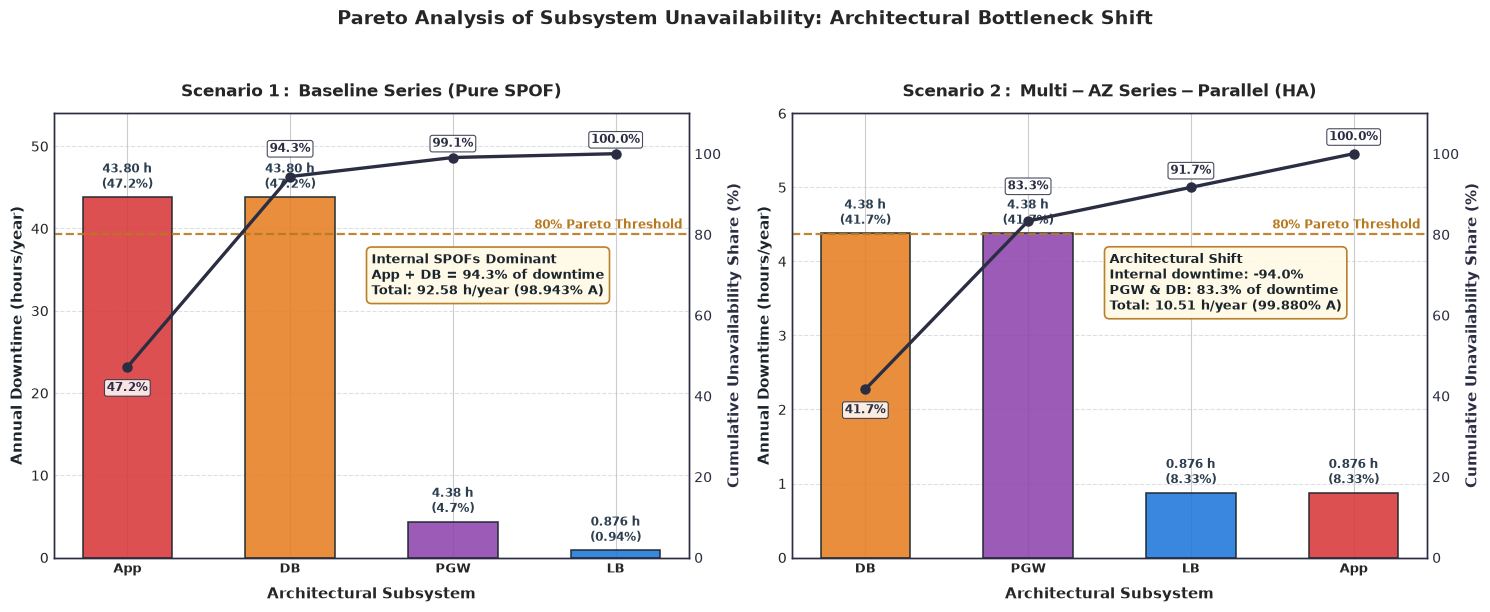

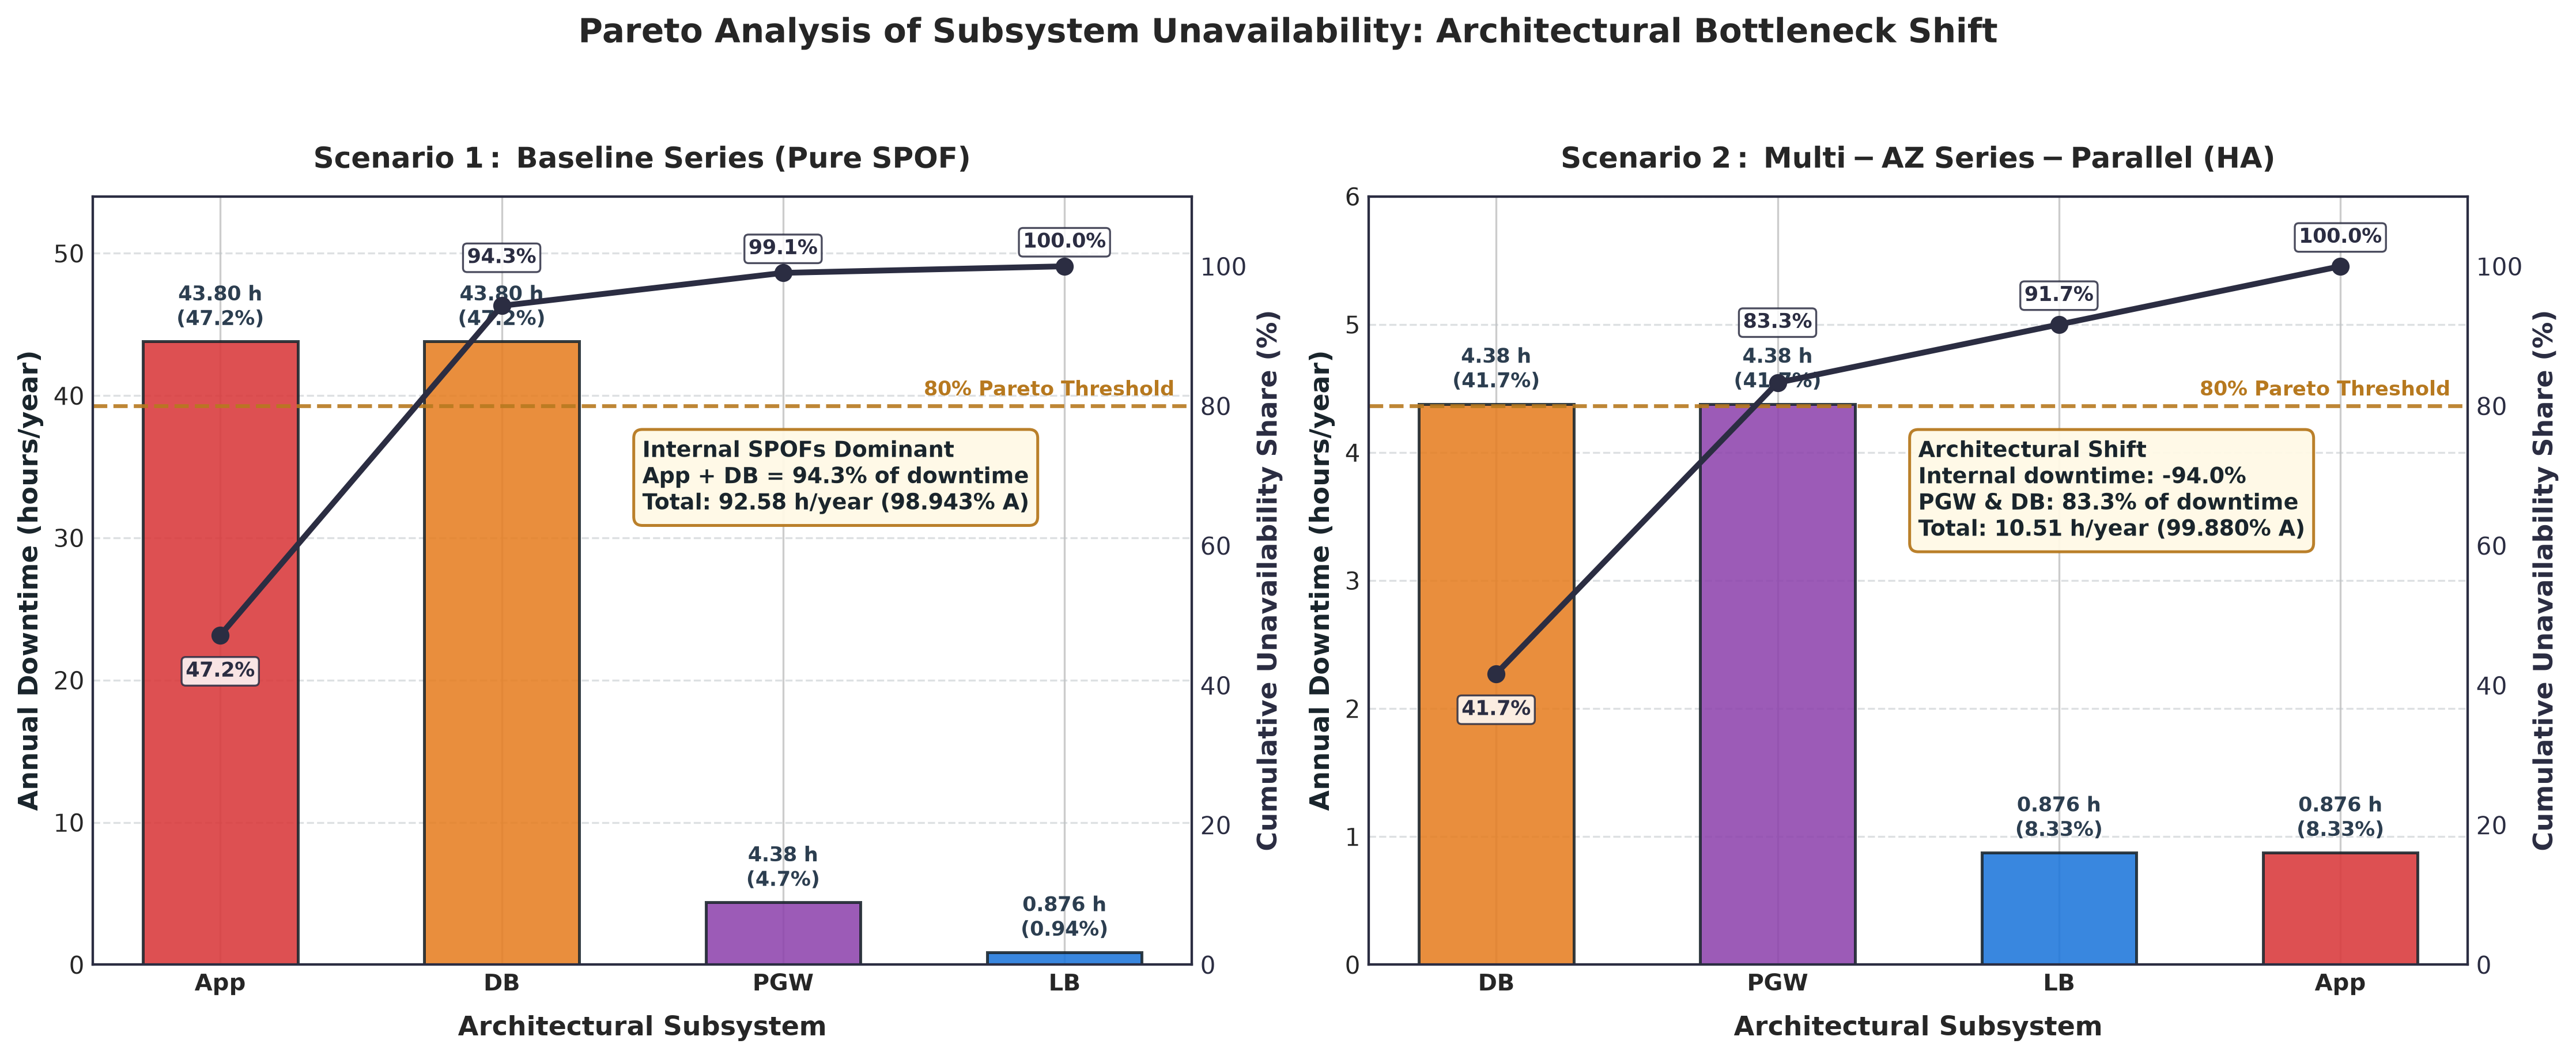

In [11]:
fig_pareto = plot_pareto_analysis(output_dir=figures_dir)
plt.show()

pareto_img_path = figures_dir / "pareto_analysis.png"
if pareto_img_path.exists():
    display(Image(filename=str(pareto_img_path), width=900))
else:
    print("Pareto analysis image not found.")


### 8.2 Quantitative Bottleneck Shift Synthesis

In [12]:
shift_rows = [
    {
        "Subsystem Tier": "Application Server (App)",
        "Scenario 1 Downtime (h/yr)": 43.800,
        "Scenario 1 Share (%)": 47.17,
        "Scenario 2 Downtime (h/yr)": 0.876,
        "Scenario 2 Share (%)": 8.33,
        "Downtime Reduction (%)": shifts["app_downtime_reduction_pct"],
        "Bottleneck Status (S2)": "Eliminated as primary bottleneck",
    },
    {
        "Subsystem Tier": "Transactional Database (DB)",
        "Scenario 1 Downtime (h/yr)": 43.800,
        "Scenario 1 Share (%)": 47.17,
        "Scenario 2 Downtime (h/yr)": 4.380,
        "Scenario 2 Share (%)": 41.67,
        "Downtime Reduction (%)": shifts["db_downtime_reduction_pct"],
        "Bottleneck Status (S2)": "Co-dominant bottleneck (Failover)",
    },
    {
        "Subsystem Tier": "Payment Gateway (PGW)",
        "Scenario 1 Downtime (h/yr)": 4.380,
        "Scenario 1 Share (%)": 4.72,
        "Scenario 2 Downtime (h/yr)": 4.380,
        "Scenario 2 Share (%)": 41.67,
        "Downtime Reduction (%)": 0.0,
        "Bottleneck Status (S2)": "Co-dominant bottleneck (External SPOF)",
    },
    {
        "Subsystem Tier": "Load Balancer (LB)",
        "Scenario 1 Downtime (h/yr)": 0.876,
        "Scenario 1 Share (%)": 0.94,
        "Scenario 2 Downtime (h/yr)": 0.876,
        "Scenario 2 Share (%)": 8.33,
        "Downtime Reduction (%)": 0.0,
        "Bottleneck Status (S2)": "Managed cloud infrastructure floor",
    },
]

df_shifts = pd.DataFrame(shift_rows)
display(df_shifts)


,Subsystem Tier,Scenario 1 Downtime (h/yr),Scenario 1 Share (%),Scenario 2 Downtime (h/yr),Scenario 2 Share (%),Downtime Reduction (%),Bottleneck Status (S2)
0,Application Server (App),43.800000,47.170000,0.876000,8.330000,98.000000,Eliminated as primary bottleneck
1,Transactional Database (DB),43.800000,47.170000,4.380000,41.670000,90.000000,Co-dominant bottleneck (Failover)
2,Payment Gateway (PGW),4.380000,4.720000,4.380000,41.670000,0.000000,Co-dominant bottleneck (External SPOF)
3,Load Balancer (LB),0.876000,0.940000,0.876000,8.330000,0.000000,Managed cloud infrastructure floor
